# BBO capstone results

This notebook rebuilds every headline number and figure from `data/` and
`results/`, then walks through one worked example of each optimisation
regime. It needs no inputs and finishes in under a minute.

Contents:
1. Results table (recomputed)
2. Progress figure
3. Calibration record
4. Regimes, worked through: EI on F3 · trust region on F7 · triangulation on F4 · parabola step on F1 · `done` on F5
5. Reproducibility check: re-deriving the round-13 queries

In [1]:
import sys, warnings, importlib.util
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bbo import data, surrogates, acquisition, triangulation
from bbo.config import CONFIG
DATA = ROOT / "data"
log = pd.read_csv(ROOT / "results" / "query_log.csv")
pd.set_option("display.precision", 10)

## 1. Results table

Computed directly from the supplied `.npy` files and the `observations.csv` files. *Records* counts the weeks that beat everything before them, including the supplied data.

In [2]:
rows = []
for i, cfg in CONFIG.items():
    X, y = data.load(DATA, i)
    n0 = len(np.load(DATA / f"function_{i}" / "initial_outputs.npy").ravel())
    run, recs = y[:n0].max(), []
    for wk, v in enumerate(y[n0:], 1):
        if v > run:
            recs.append(wk); run = v
    k = int(np.argmax(y))
    rows.append(dict(fn=f"F{i}", dim=cfg["dim"], supplied=n0, queried=len(y) - n0,
                     initial_best=y[:n0].max(), final_best=y.max(),
                     gain=y.max() - y[:n0].max(), best_week=k - n0 + 1,
                     records=len(recs), best_point=data.portal_format(X[k]),
                     regime=cfg["regime"]))
results = pd.DataFrame(rows).set_index("fn")
print(f"{results.records.sum()} records across {results.queried.sum()} graded queries")
results

47 records across 103 graded queries


,dim,supplied,queried,initial_best,final_best,gain,best_week,records,best_point,regime
fn,,,,,,,,,,
F1,2,10,13,7.7108751145e-16,1.9999998885,1.9999998885,13,8,0.628535-0.628540,micro
F2,2,10,13,6.1120521576e-01,0.7472263869,0.1360211711,13,4,0.691881-0.999999,lottery
F3,3,15,13,-3.4835313350e-02,-0.0081868589,0.0266484544,5,1,0.483975-0.760029-0.488443,trust_region
F4,4,30,13,-4.0255422819e+00,0.6023985048,4.6279407867,13,9,0.408778-0.401009-0.365086-0.411411,triangulate
F5,4,20,12,1.0888596182e+03,8662.4050012483,7573.5453830520,7,6,0.999999-0.999999-0.999999-0.999999,done
F6,5,20,13,-7.1426494782e-01,-0.0610977580,0.6531671898,13,6,0.439225-0.342711-0.688900-0.766119-0.155571,trust_region
F7,6,30,13,1.3649683045e+00,2.8264462034,1.4614778989,13,6,0.000001-0.150045-0.470479-0.285731-0.317670-0...,trust_region
F8,8,40,13,9.5984820026e+00,9.9518159888,0.3533339862,13,7,0.095725-0.148082-0.133402-0.000001-0.949999-0...,trust_region


## 2. Progress

The blue staircase is the best value so far. Grey dots are the weekly readings, and the dashed line is the best value in the supplied data. Triangles mark readings that fall below the axis.

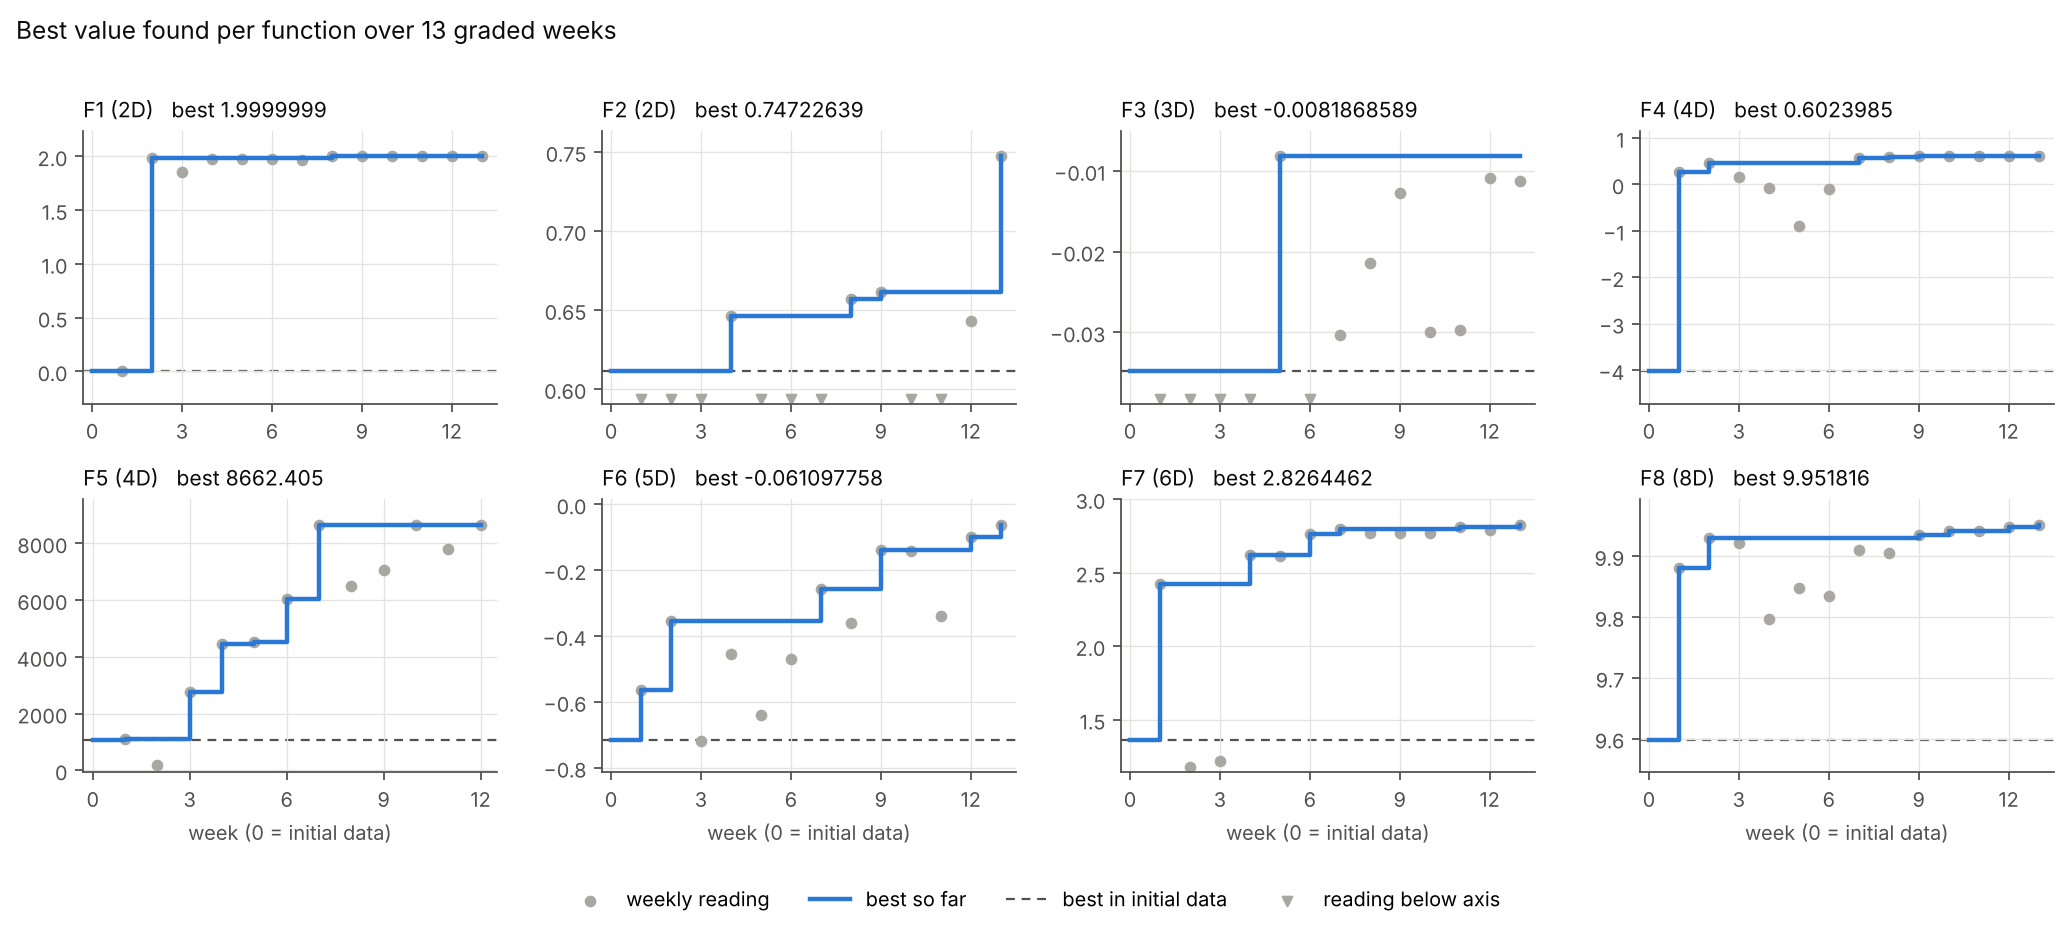

In [3]:
spec = importlib.util.spec_from_file_location("make_figures", ROOT / "scripts" / "make_figures.py")
mf = importlib.util.module_from_spec(spec); spec.loader.exec_module(mf)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
mf.best_so_far(DATA, FIG)
display(Image(FIG / "best_so_far.png"))

## 3. Calibration record

Every query went in with a written prediction and range. The next result graded it. This is the only test of the surrogate at points it has not yet seen, which is exactly where it is used.

overall: 76/95 = 80% of predictions inside their stated range


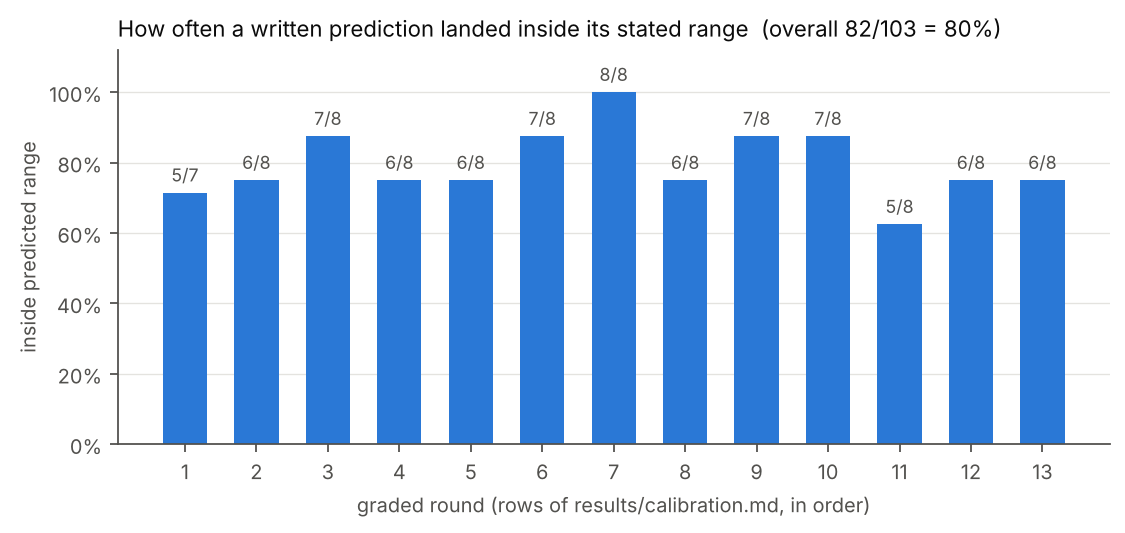

,round,hits,of,notes
0,1->2,5,7,"F4, F7 upside; F1 quadratic missed badly -> re..."
1,2->3,6,8,F1 re-triangulation jackpot (+1.989 from ~0)
2,3->4,7,8,F4 hard miss -> trust region; F5 corner +44% (...
3,4->5,6,8,"F2 ""noise"" measured; F4 crash -> box shrunk"
4,5->6,6,8,F3 overconfident sd; F5 +33% upside (6028)
5,6->7,7,8,"F7 4th record, prediction nearly exact"
6,7->8,8,8,perfect week; F1 fit predicted 2.0009 -> obser...
7,8->9,6,8,F6 upside break -0.137
8,9->10,7,8,F8 plateau cracked
9,10->11,7,8,DETERMINISM PROVEN (F5 bit-identical); F8 9.9405


In [4]:
import re
txt = (ROOT / "results" / "calibration.md").read_text()
cal = pd.DataFrame(re.findall(r"^\|\s*(\d+->\s*\d+)\s*\|\s*(\d+)/(\d+)\s*\|\s*(.*?)\s*\|$", txt, flags=re.M),
                   columns=["round", "hits", "of", "notes"]).astype({"hits": int, "of": int})
print(f"overall: {cal.hits.sum()}/{cal.of.sum()} = {cal.hits.sum()/cal.of.sum():.0%} of predictions inside their stated range")
mf.calibration_hits(ROOT / "results", FIG)
display(Image(FIG / "calibration_hits.png"))
cal

## 4. The regimes, worked through

### 4a. Expected Improvement over the whole domain vs a local box: F3

With lengthscales capped at 0.2, EI over the whole domain still prefers
unexplored regions, because the GP's uncertainty is large there. The
trust-region box keeps the proposal next to the spike at (0.484, 0.760, 0.488).

In [5]:
cfg = CONFIG[3]
X, y = data.load(DATA, 3)
gp = surrogates.fit_gp(X, y, ls_hi=cfg["ls_hi"])
inc = X[np.argmax(y)]
for name, kw in [("whole-domain EI (xi=0.01)", dict(xi=0.01)),
                 ("trust region (xi=0)", dict(xi=0.0, lo=inc - cfg["box_half"], hi=inc + cfg["box_half"]))]:
    q, _ = acquisition.propose(gp, 3, y.max(), **kw)
    mu, sd = gp.predict(q.reshape(1, -1), return_std=True)
    print(f"{name:28s} {data.portal_format(q)}  mu={mu[0]:+.4f} sd={sd[0]:.4f}  distance from incumbent={np.linalg.norm(q - inc):.3f}")
print("fitted lengthscales:", np.round(gp.kernel_.k2.length_scale, 3))

whole-domain EI (xi=0.01)    0.408013-0.573485-0.495243  mu=-0.0315 sd=0.0571  distance from incumbent=0.202
trust region (xi=0)          0.488978-0.754029-0.482443  mu=-0.0042 sd=0.0024  distance from incumbent=0.010
fitted lengthscales: [0.083 0.2   0.2  ]


### 4b. Trust region with capped lengthscales: F7

F7's ridge is sharp, so the box half-width is only 0.008. The proposal moves only a few thousandths along each input.

incumbent: 0.000001-0.150045-0.470479-0.285731-0.317670-0.677665 y=2.826446
proposal:  0.000001-0.143280-0.472692-0.277731-0.313241-0.669665 mu=2.8373 +/- 0.0024
step per input: [ 0.     -0.0068  0.0022 -0.008  -0.0044 -0.008 ]


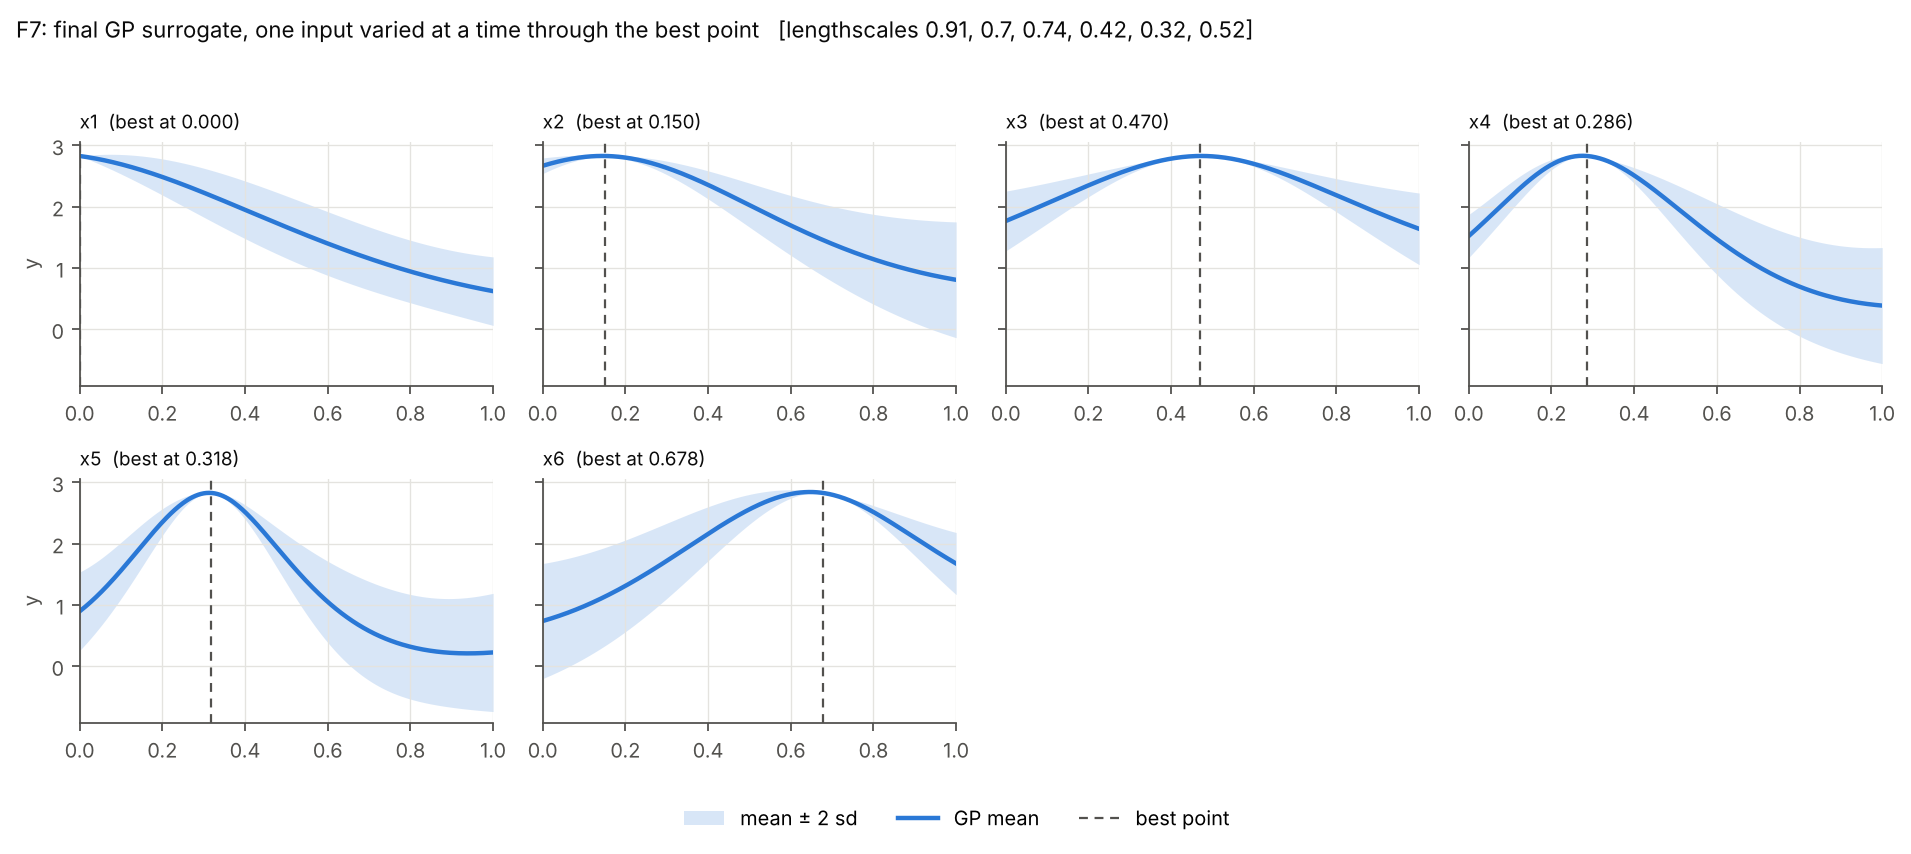

In [6]:
cfg = CONFIG[7]
X, y = data.load(DATA, 7)
gp = surrogates.fit_gp(X, y, ls_hi=cfg["ls_hi"])
inc = X[np.argmax(y)]
q, _ = acquisition.propose(gp, 6, y.max(), xi=0.0, lo=inc - cfg["box_half"], hi=inc + cfg["box_half"])
mu, sd = gp.predict(q.reshape(1, -1), return_std=True)
print("incumbent:", data.portal_format(inc), f"y={y.max():.6f}")
print("proposal: ", data.portal_format(q), f"mu={mu[0]:.4f} +/- {sd[0]:.4f}")
print("step per input:", np.round(q - inc, 4))
display(Image(FIG / "surrogate_F7.png"))

### 4c. Parametric triangulation: F4

An isotropic quadratic `a + b·x + c·|x|²` is fitted to the raw readings within 0.13 of the incumbent. Its vertex is the next query, and that vertex is exactly the round-13 submission.

In [7]:
X, y = data.load(DATA, 4)
inc = X[np.argmax(y)]
c, peak, r2, ok = triangulation.triangulate(X, y, radius=CONFIG[4]["radius"], anchor=inc, use_log_magnitude=False)
print(f"fit ok={ok}  R2={r2:.4f}  fitted peak={peak:.4f}")
print("vertex        :", data.portal_format(c))
print("submitted wk13:", log["query"][(log.week == 13) & (log.function == "F4")].item())
print("F4 weeks 7-12 :", np.round(y[-6:], 5))

fit ok=True  R2=0.9945  fitted peak=0.6079
vertex        : 0.408773-0.401037-0.365095-0.411414
submitted wk13: 0.408778-0.401009-0.365086-0.411411
F4 weeks 7-12 : [0.59781 0.60035 0.60134 0.60186 0.60219 0.6024 ]


### 4d. 1D parabola step: F1

Near F1's peak, the 2D fit runs out of precision. With x1 fixed at 0.628534, three readings along x2 determine a parabola, and its vertex gave the week-12 query.

          x1        x2             y
9   0.628534  0.628592  1.9999867666
10  0.628534  0.628591  1.9999872628
11  0.628534  0.628531  1.9999994645
12  0.628534  0.628540  1.9999998375

parabola through weeks 9-11 along x2: vertex x2=0.628540, predicted y=1.999999838
week-12 query:                      x2=0.628540, observed  y=1.999999837
refit including week 12: vertex x2=0.628540 -> x2 has converged, so week 13 moves x1 by 1e-6 instead


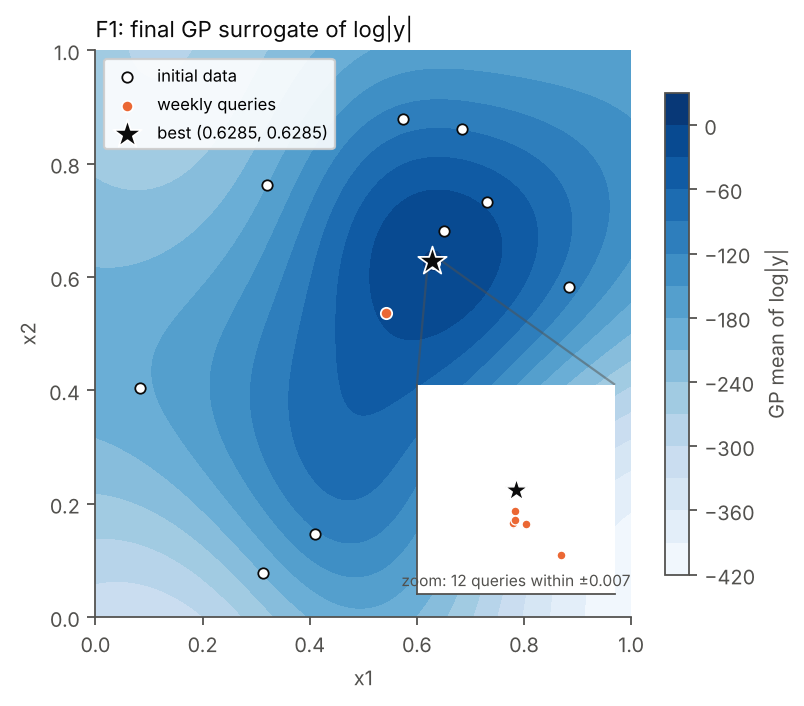

In [8]:
X, y = data.load(DATA, 1)
n0 = 10
W = pd.DataFrame(np.column_stack([X[n0:], y[n0:]]), columns=["x1", "x2", "y"]); W.index = range(1, len(W) + 1)
print(W.loc[9:12].to_string())
wk = lambda w: n0 + w - 1  # row index of week w
v, pred = triangulation.parabola_step(X[[wk(9), wk(10), wk(11)], 1], y[[wk(9), wk(10), wk(11)]])
print(f"\nparabola through weeks 9-11 along x2: vertex x2={v:.6f}, predicted y={pred:.9f}")
print(f"week-12 query:                      x2={X[wk(12), 1]:.6f}, observed  y={y[wk(12)]:.9f}")
v2, _ = triangulation.parabola_step(X[[wk(9), wk(11), wk(12)], 1], y[[wk(9), wk(11), wk(12)]])
print(f"refit including week 12: vertex x2={v2:.6f} -> x2 has converged, so week 13 moves x1 by 1e-6 instead")
display(Image(FIG / "surrogate_F1.png"))

### 4e. `done`: F5

The corner was queried three times and returned the same value bit-for-bit, which shows the functions are deterministic. Stepping back from the corner along each input lost value every time, so the corner is the maximum within the box.

In [9]:
f5 = log[log.function == "F5"].copy()
f5["x"] = f5["query"].str.split("-")
f5["at_corner"] = f5.x.apply(lambda v: all(c == "0.999999" for c in v))
print("corner readings:", f5.loc[f5.at_corner & f5.observed.notna(), ["week", "observed"]].to_dict("records"))
f5[["week", "query", "observed"]].tail(6)

corner readings: [{'week': 7, 'observed': 8662.405001248297}, {'week': 10, 'observed': 8662.405001248297}, {'week': 12, 'observed': 8662.405001248297}, {'week': 13, 'observed': 8662.405001248297}]


,week,query,observed
60,8,0.999999-0.850000-0.999999-0.999999,6495.0315739000
68,9,0.999999-0.999999-0.900000-0.999999,7073.3929968159
76,10,0.999999-0.999999-0.999999-0.999999,8662.4050012483
84,11,0.999999-0.999999-0.999999-0.950000,7786.3162513509
92,12,0.999999-0.999999-0.999999-0.999999,8662.4050012483
100,13,0.999999-0.999999-0.999999-0.999999,8662.4050012483


## 5. Reproducibility: re-deriving the round-13 queries

On the final data, the driver regenerates the submitted round-13 queries for the functions with an automatic regime. F1 and F2 were hand-crafted endgames (`micro`, `lottery`).

In [10]:
import subprocess
outp = subprocess.run([sys.executable, str(ROOT / "scripts" / "weekly_run.py"), "--data", str(DATA)],
                      capture_output=True, text=True).stdout
derived = {l.split(":")[0]: l.split()[1] for l in outp.splitlines() if l.startswith("F") and "regime '" not in l}
sub = log[log.week == 13].set_index("function")["query"]
chk = pd.DataFrame({"submitted": sub, "re-derived": pd.Series(derived)})
def maxdiff(r):
    if not isinstance(r["re-derived"], str): return None
    a = np.array(r.submitted.split("-"), float); b = np.array(r["re-derived"].split("-"), float)
    return float(np.abs(a - b).max())
chk["max |diff|"] = chk.apply(maxdiff, axis=1)
chk

,submitted,re-derived,max |diff|
F1,0.628535-0.628540,NaN,NaN
F2,0.691881-0.999999,NaN,NaN
F3,0.489975-0.766029-0.494443,0.488978-0.754029-0.482443,0.012000
F4,0.408778-0.401009-0.365086-0.411411,0.408773-0.401037-0.365095-0.411414,0.000028
F5,0.999999-0.999999-0.999999-0.999999,0.999999-0.999999-0.999999-0.999999,0.000000
F6,0.439225-0.342711-0.688900-0.766119-0.155571,0.420969-0.347111-0.708900-0.767120-0.135571,0.020000
F7,0.000001-0.150045-0.470479-0.285731-0.317670-0...,0.000001-0.143280-0.472692-0.277731-0.313241-0...,0.008000
F8,0.095725-0.148082-0.133402-0.000001-0.949999-0...,0.098136-0.147814-0.132701-0.000001-0.934999-0...,0.015000
